# 03 - Visualize discharge

Create and display two meaningful plots for each basin, and save copies for the README.



## Imports, paths, and inputs

The path setup works from the repository root or its notebook subfolder. Earlier stages must be run before later stages.

In [1]:
%matplotlib inline

No event loop hook running.


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# VS Code may start in the project root or in the notebook folder.
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Open the project containing data/raw, and download the subset first.")
print("Project folder:", ROOT)
OUT = ROOT / "results" / "staged" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(ROOT / "data/processed/caravan_selected.csv", parse_dates=["date"])
study = data[data["date"].between("1990-01-01", "2014-12-31")]

Project folder: /workspace/scratch/5a6f9ec1ab8c/Early-Flash-Flood-Prediction


## Draw the figures

Time series show sharp peaks and changing flow. The histograms have long right tails: very high flows are rare. The count axis is logarithmic. Missing periods are gaps, not zero flow.

Saved two figures for camels_01411300
Saved two figures for camels_05495500
Saved two figures for camels_14182500


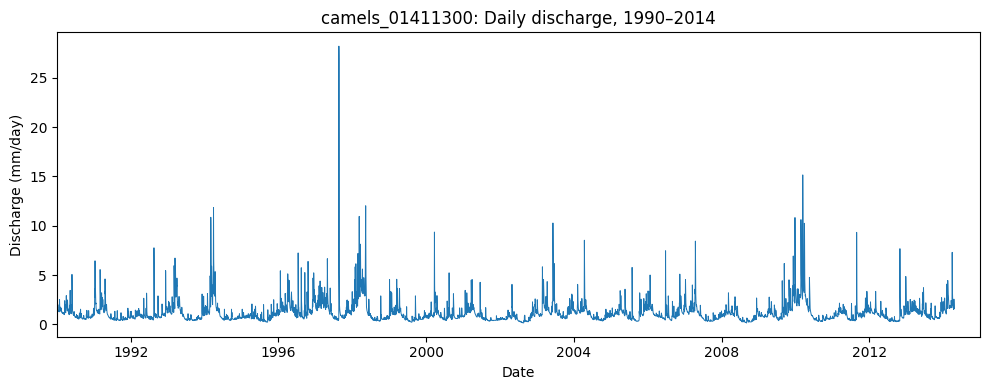

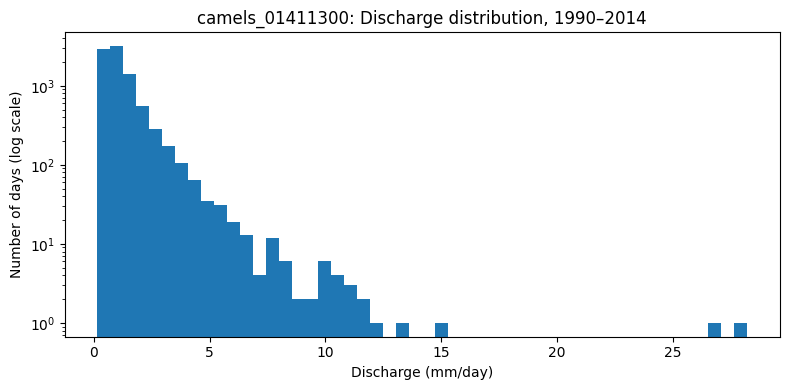

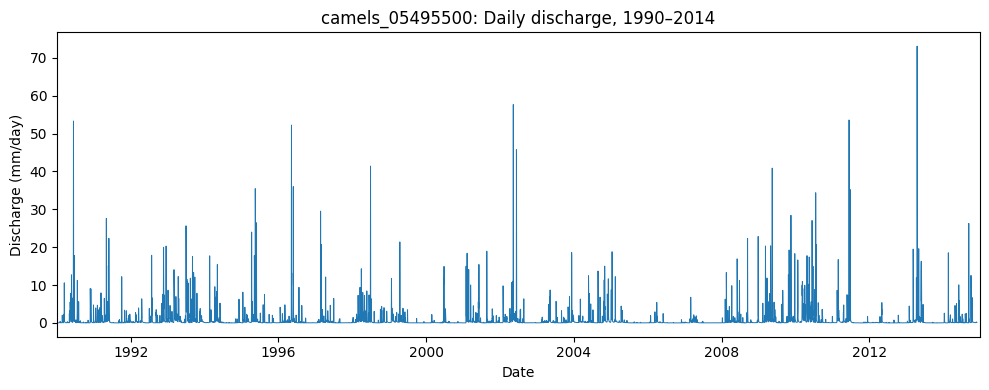

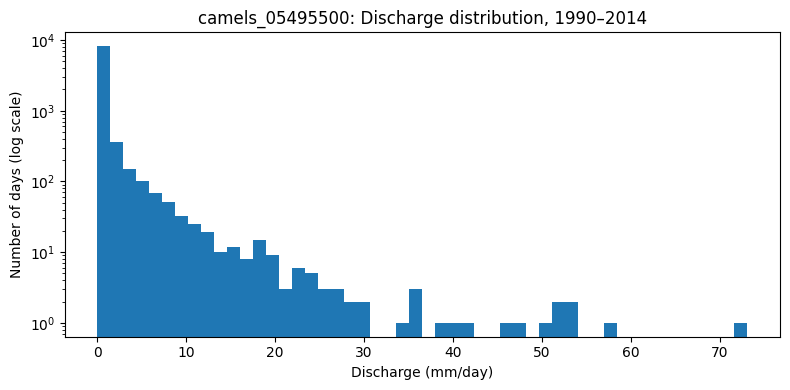

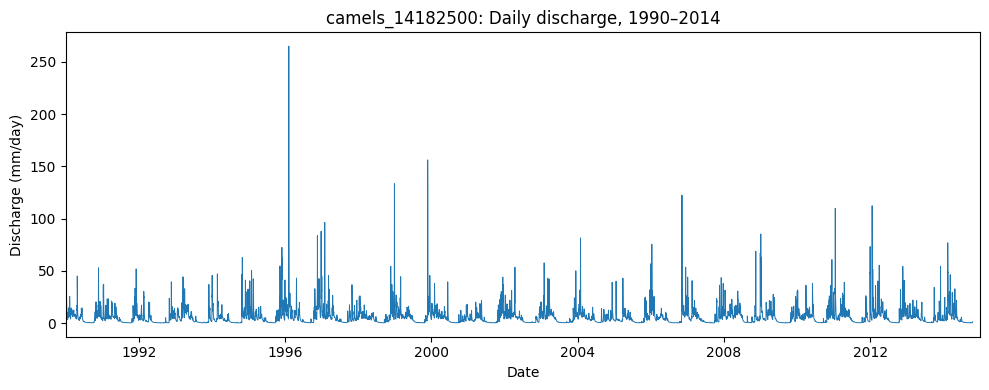

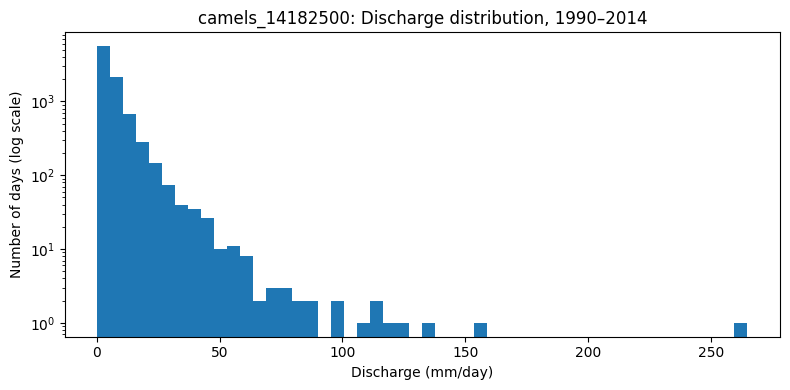

In [3]:
for basin, df in study.groupby("basin"):
    # Explicit missing dates prevent lines from joining across calendar gaps.
    df = df.set_index("date").sort_index().asfreq("D")
    df.loc[df["streamflow"] < 0, "streamflow"] = float("nan")

    plt.figure(figsize=(10, 4))
    plt.plot(df.index, df["streamflow"], linewidth=0.7)
    plt.title(f"{basin}: Daily discharge, 1990–2014")
    plt.xlabel("Date")
    plt.ylabel("Discharge (mm/day)")
    plt.xlim(pd.Timestamp("1990-01-01"), pd.Timestamp("2014-12-31"))
    plt.tight_layout()
    plt.savefig(OUT / f"{basin}_discharge.png", dpi=150)
    plt.show()
    plt.close()

    plt.figure(figsize=(8, 4))
    plt.hist(df["streamflow"].dropna(), bins=50)
    plt.yscale("log")
    plt.title(f"{basin}: Discharge distribution, 1990–2014")
    plt.xlabel("Discharge (mm/day)")
    plt.ylabel("Number of days (log scale)")
    plt.tight_layout()
    plt.savefig(OUT / f"{basin}_distribution.png", dpi=150)
    plt.show()
    plt.close()
    print("Saved two figures for", basin)

## Inspect the output

In [4]:
print("Figures saved in:", OUT)

Figures saved in: /workspace/scratch/5a6f9ec1ab8c/Early-Flash-Flood-Prediction/results/staged/figures


## What this means

Time series show sharp peaks and changing flow. The histograms have long right tails: very high flows are rare. The count axis is logarithmic. Missing periods are gaps, not zero flow.

**Scope:** next-day river discharge. ERA5-Land is retrospective weather reanalysis and may not be available at the assumed end-of-day origin. Operational availability, high-flow detection, 7–14-day forecasts, and transfer to new regions remain future work.